In [20]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd

from torchvision.models import resnet34
from sklearn.metrics import roc_auc_score

from src.dataset import ChestXrayDataset, RepeatChannels, PoissonNoise

from torch.utils.data import DataLoader
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [3]:
import timm

model = timm.create_model(
    "vit_small_patch16_224.augreg_in1k",
    pretrained=False,
    num_classes=14
)

checkpoint = torch.load(
    "checkpoints/vit_s16_adamw_clean_epoch_1.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False

## Performance of different Epoch on clean dataset

In [32]:
train_df = pd.read_csv("metadata/train.csv")
val_df = pd.read_csv("metadata/val.csv")
data_dir = "data/data"
vit_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    RepeatChannels(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

train_dataset = ChestXrayDataset(
    dataframe=train_df,
    data_dir=str(data_dir),
    transform=vit_transform,
    image_mode="L"
)
val_dataset = ChestXrayDataset(
    val_df,
    data_dir=str(data_dir),
    transform=vit_transform,
    image_mode="L"
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    #persistent_workers=True
)

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

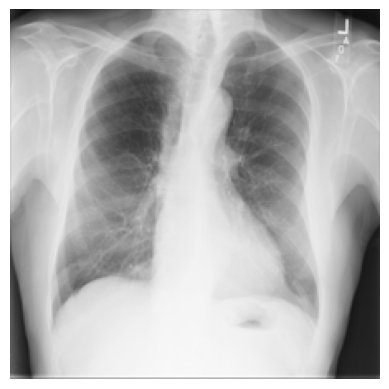

In [33]:
import matplotlib.pyplot as plt
image, label = val_dataset[0]

# Reverse ImageNet normalization
mean = torch.tensor([0.5, 0.5, 0.5])[:, None, None]
std = torch.tensor([0.5, 0.5, 0.5])[:, None, None]

image = (image * std + mean).clamp(0, 1)

plt.imshow(image[0], cmap="gray", vmin=0, vmax=1)
plt.axis("off")

In [11]:
from src.evaluate import load_checkpoint, evaluate_model

In [25]:
pathology_names = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration",
    "Mass", "Nodule", "Pneumonia", "Pneumothorax",
    "Consolidation", "Edema", "Emphysema", "Fibrosis",
    "Pleural Thickening", "Hernia"
]

model = load_checkpoint(
    model,
    "checkpoints/vit_s16_adamw_clean_epoch_3.pth",
    device
)

df, macro_auc = evaluate_model(
    model,
    val_loader,
    device,
    pathology_names
)

display(df)

Loaded epoch: 3
Processed 100/342 batches | Interval: 19.9 s | Elapsed: 0.3 min | ETA: 0.8 min
Processed 200/342 batches | Interval: 20.2 s | Elapsed: 0.7 min | ETA: 0.5 min
Processed 300/342 batches | Interval: 20.0 s | Elapsed: 1.0 min | ETA: 0.1 min
Processed 342/342 batches | Interval: 8.1 s | Elapsed: 1.1 min | ETA: 0.0 min

Macro ROC-AUC: 0.7908
Total evaluation time: 1.14 min


,Name,ROC AUC
0,Atelectasis,0.803013
1,Cardiomegaly,0.870427
2,Effusion,0.854216
3,Infiltration,0.719535
4,Mass,0.809443
5,Nodule,0.681017
6,Pneumonia,0.743878
7,Pneumothorax,0.835697
8,Consolidation,0.787384
9,Edema,0.905639


## Performance on Noisy data

In [27]:
#sanity check
poisson_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    PoissonNoise(peak=10000),
    RepeatChannels(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

val_dataset = ChestXrayDataset(
    val_df,
    data_dir=str(data_dir),
    transform=poisson_transform,
    image_mode="L"
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    #persistent_workers=True
)

poisson_df, poisson_auc = evaluate_model(
    model,
    val_loader,
    device,
    pathology_names
)


Processed 100/342 batches | Interval: 41.4 s | Elapsed: 0.7 min | ETA: 1.7 min
Processed 200/342 batches | Interval: 41.9 s | Elapsed: 1.4 min | ETA: 1.0 min
Processed 300/342 batches | Interval: 40.6 s | Elapsed: 2.1 min | ETA: 0.3 min
Processed 342/342 batches | Interval: 16.8 s | Elapsed: 2.3 min | ETA: 0.0 min

Macro ROC-AUC: 0.7908
Total evaluation time: 2.35 min


In [28]:
poisson_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    PoissonNoise(peak=250),
    RepeatChannels(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

val_dataset = ChestXrayDataset(
    val_df,
    data_dir=str(data_dir),
    transform=poisson_transform,
    image_mode="L"
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    #persistent_workers=True
)

poisson_df, poisson_auc = evaluate_model(
    model,
    val_loader,
    device,
    pathology_names
)


Processed 100/342 batches | Interval: 44.4 s | Elapsed: 0.7 min | ETA: 1.8 min
Processed 200/342 batches | Interval: 46.1 s | Elapsed: 1.5 min | ETA: 1.1 min
Processed 300/342 batches | Interval: 46.2 s | Elapsed: 2.3 min | ETA: 0.3 min
Processed 342/342 batches | Interval: 18.8 s | Elapsed: 2.6 min | ETA: 0.0 min

Macro ROC-AUC: 0.7616
Total evaluation time: 2.59 min


(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

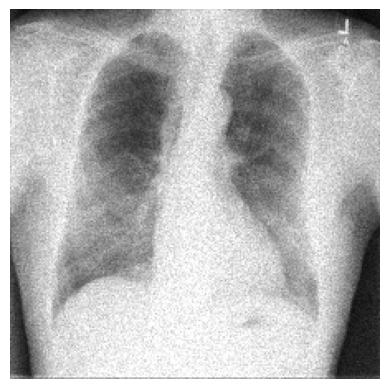

In [31]:
import matplotlib.pyplot as plt
image, label = val_dataset[0]

# Reverse ImageNet normalization
mean = torch.tensor([0.5, 0.5, 0.5])[:, None, None]
std = torch.tensor([0.5, 0.5, 0.5])[:, None, None]

image = (image * std + mean).clamp(0, 1)

plt.imshow(image[0], cmap="gray", vmin=0, vmax=1)
plt.axis("off")

In [35]:
import time
peaks = ["Clean", 10000, 5000, 2000, 1000, 250, 25]

vit_results = []

for peak in peaks:
    print(f"\nEvaluating ViT epoch 3: peak={peak}")

    transform_steps = [
        transforms.Resize(
            (224, 224),
            interpolation=transforms.InterpolationMode.BICUBIC
        ),
        transforms.ToTensor(),
    ]

    if peak != "Clean":
        transform_steps.append(PoissonNoise(peak=peak))

    transform_steps.extend([
        RepeatChannels(),
        transforms.Normalize(
            mean=[0.5, 0.5, 0.5],
            std=[0.5, 0.5, 0.5]
        )
    ])

    val_dataset = ChestXrayDataset(
        dataframe=val_df,
        data_dir=str(data_dir),
        transform=transforms.Compose(transform_steps),
        image_mode="L"
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    # Reproducible noise generation for this run
    torch.manual_seed(42)

    start = time.perf_counter()

    _, macro_auc = evaluate_model(
        model,
        val_loader,
        device,
        pathology_names
    )

    elapsed = (time.perf_counter() - start) / 60

    vit_results.append({
        "Model": "ViT-S/16 Epoch 3",
        "Peak": str(peak),
        "Macro_AUROC": macro_auc,
        "Evaluation_Minutes": elapsed
    })

vit_df = pd.DataFrame(vit_results)
display(vit_df)

vit_df.to_csv(
    "vit_epoch3_macro_auroc.csv",
    index=False
)



Evaluating ViT epoch 3: peak=Clean
Processed 100/342 batches | Interval: 20.0 s | Elapsed: 0.3 min | ETA: 0.8 min
Processed 200/342 batches | Interval: 20.7 s | Elapsed: 0.7 min | ETA: 0.5 min
Processed 300/342 batches | Interval: 20.6 s | Elapsed: 1.0 min | ETA: 0.1 min
Processed 342/342 batches | Interval: 8.3 s | Elapsed: 1.2 min | ETA: 0.0 min

Macro ROC-AUC: 0.7908
Total evaluation time: 1.16 min

Evaluating ViT epoch 3: peak=10000
Processed 100/342 batches | Interval: 38.2 s | Elapsed: 0.6 min | ETA: 1.5 min
Processed 200/342 batches | Interval: 39.8 s | Elapsed: 1.3 min | ETA: 0.9 min
Processed 300/342 batches | Interval: 39.3 s | Elapsed: 2.0 min | ETA: 0.3 min
Processed 342/342 batches | Interval: 15.8 s | Elapsed: 2.2 min | ETA: 0.0 min

Macro ROC-AUC: 0.7906
Total evaluation time: 2.22 min

Evaluating ViT epoch 3: peak=5000
Processed 100/342 batches | Interval: 39.6 s | Elapsed: 0.7 min | ETA: 1.6 min


KeyboardInterrupt: 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
resnet_df = pd.read_csv("results/macro_auroc.csv")
vit_df = pd.read_csv("results/vit_epoch3_macro_auroc.csv")
vit_poisson_df = pd.read_csv(
    "results/vit_poisson250_epoch5_macro_auroc.csv"
)
combined_df = pd.concat(
    [resnet_df, vit_df, vit_poisson_df],
    ignore_index=True
)

combined_df["Peak"] = combined_df["Peak"].astype(str)

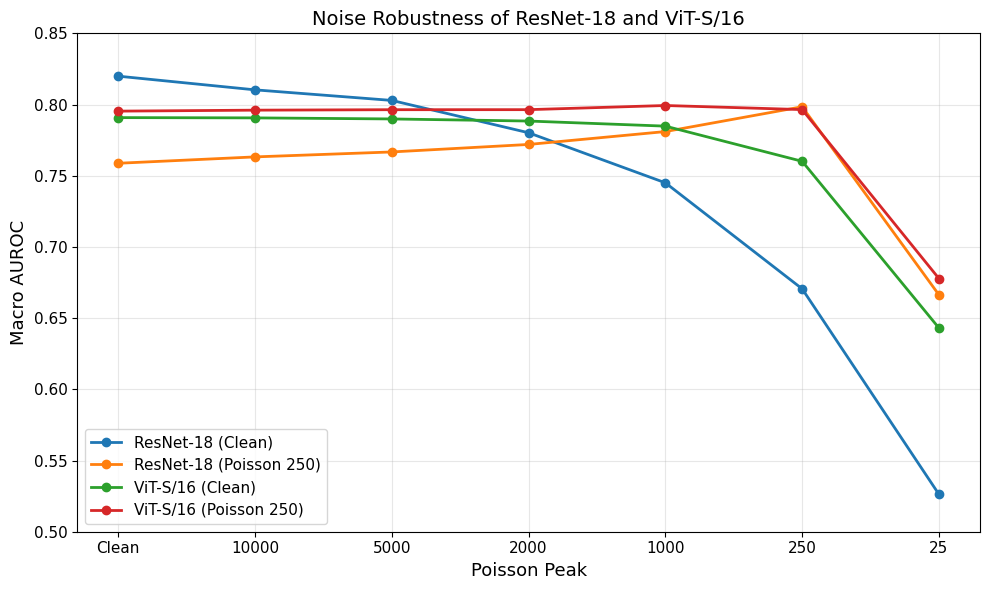

In [3]:
peak_order = ["Clean", "10000", "5000", "2000", "1000", "250", "25"]

model_labels = {
    "Original": "ResNet-18 (Clean)",
    "Poisson_Epoch5": "ResNet-18 (Poisson 250)",
    "ViT-S/16 Epoch 3": "ViT-S/16 (Clean)",
    "ViT-S/16 Poisson250 Epoch 5": "ViT-S/16 (Poisson 250)"
}

plt.figure(figsize=(10, 6))

for model, label in model_labels.items():

    subset = combined_df[combined_df["Model"] == model]

    subset = (
        subset.drop_duplicates(subset="Peak")
        .set_index("Peak")
        .reindex(peak_order)
    )

    plt.plot(
        peak_order,
        subset["Macro_AUROC"],
        marker="o",
        linewidth=2,
        markersize=6,
        label=label
    )

plt.xlabel("Poisson Peak", fontsize=13)
plt.ylabel("Macro AUROC", fontsize=13)
plt.title("Noise Robustness of ResNet-18 and ViT-S/16", fontsize=14)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.ylim(0.5, 0.85)

plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '../results/resnet_vit_noise_robustness.pdf'

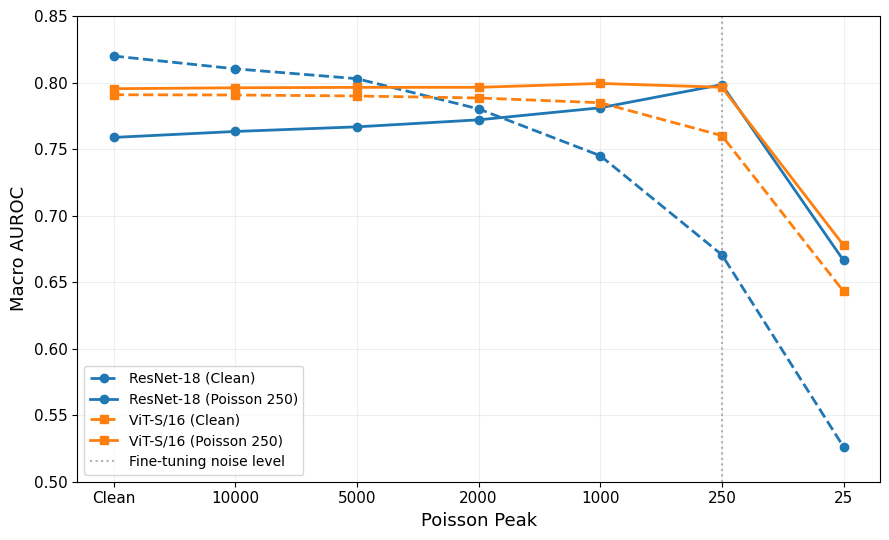

In [4]:
model_styles = {
    "Original": {
        "label": "ResNet-18 (Clean)",
        "color": "tab:blue",
        "linestyle": "--",
        "marker": "o"
    },
    "Poisson_Epoch5": {
        "label": "ResNet-18 (Poisson 250)",
        "color": "tab:blue",
        "linestyle": "-",
        "marker": "o"
    },
    "ViT-S/16 Epoch 3": {
        "label": "ViT-S/16 (Clean)",
        "color": "tab:orange",
        "linestyle": "--",
        "marker": "s"
    },
    "ViT-S/16 Poisson250 Epoch 5": {
        "label": "ViT-S/16 (Poisson 250)",
        "color": "tab:orange",
        "linestyle": "-",
        "marker": "s"
    }
}

fig, ax = plt.subplots(figsize=(9, 5.5))

for model, style in model_styles.items():

    subset = (
        combined_df[combined_df["Model"] == model]
        .drop_duplicates(subset="Peak")
        .set_index("Peak")
        .reindex(peak_order)
    )

    ax.plot(
        peak_order,
        subset["Macro_AUROC"],
        linewidth=2,
        markersize=6,
        **style
    )

ax.axvline(
    x=5,
    color="gray",
    linestyle=":",
    alpha=0.6,
    label="Fine-tuning noise level"
)

ax.set_xlabel("Poisson Peak", fontsize=13)
ax.set_ylabel("Macro AUROC", fontsize=13)
ax.set_ylim(0.5, 0.85)
ax.tick_params(labelsize=11)
ax.grid(alpha=0.2)
ax.legend(fontsize=10)

fig.tight_layout()

fig.savefig(
    "../results/resnet_vit_noise_robustness.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "../results/resnet_vit_noise_robustness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

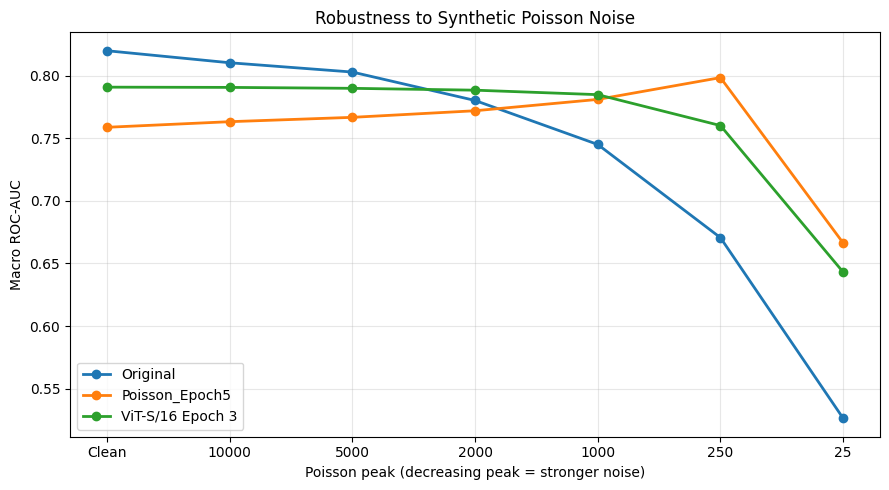

In [40]:
import matplotlib.pyplot as plt

models_to_plot = [
    "Original",
    "Poisson_Epoch5",
    "ViT-S/16 Epoch 3"
]

peak_order = ["Clean", "10000", "5000", "2000", "1000", "250", "25"]

plot_df = combined_df[
    combined_df["Model"].isin(models_to_plot)
].copy()

plt.figure(figsize=(9, 5))

for model_name, group in plot_df.groupby("Model"):
    auc_values = (
        group.set_index("Peak")
        .reindex(peak_order)["Macro_AUROC"]
    )

    plt.plot(
        range(len(peak_order)),
        auc_values,
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xticks(range(len(peak_order)), peak_order)
plt.xlabel("Poisson peak (decreasing peak = stronger noise)")
plt.ylabel("Macro ROC-AUC")
plt.title("Robustness to Synthetic Poisson Noise")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()